# AATD · Notebook 1: Data understanding e Data preparation

Projeto de **Algoritmos de Apoio à Tomada de Decisão** (FEP, 2026/27).
Objetivo: prever se um produto está em promoção (`y=1`) a partir das suas características. A métrica é a **accuracy**.

Este notebook cobre os capítulos *Business understanding*, *Data understanding* e *Data preparation* do relatório.
Guarda em `outputs/` as figuras, as tabelas e os folds da cross-validation que o Notebook 2 usa.

Para correr: coloca `training.csv` e `task.csv` na pasta `data/` (ou ao lado do notebook).

# Import Packages/Libraries

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

SEED = 42
DATA = Path("data") if Path("data/training.csv").exists() else Path(".")
OUT = Path("outputs"); FIG = OUT / "figuras"; TAB = OUT / "tabelas"
for p in (FIG, TAB):
    p.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
COR = "#3b6ea5"


def guardar_fig(nome):
    plt.savefig(FIG / f"{nome}.png", dpi=150, bbox_inches="tight")
    plt.show()

# Business understanding

Os produtos são vendidos por vários estabelecimentos e, por vezes, estão em promoção. O problema é **classificar** cada produto
como *com desconto* (`y=1`) ou *sem desconto* (`y=0`) usando as suas características.

- A decisão apoiada: antecipar que produtos estão em promoção.
- A métrica de avaliação da competição é a **accuracy**, a proporção de produtos classificados corretamente.
- Só é possível **uma submissão**, por isso o modelo final escolhe-se apenas pela validação cruzada.
- Como as classes estão desbalanceadas, a accuracy tem de ser lida contra a **baseline** de prever sempre a classe maioritária
  (calculada abaixo). O Recall, a Precision e o F-measure da classe `y=1` completam a comparação.

# Data understanding

### Read the data

In [2]:
training = pd.read_csv(DATA / "training.csv")
task = pd.read_csv(DATA / "task.csv")
print("training:", training.shape, "| task:", task.shape)
training.head(6)

training: (3676, 28) | task: (3676, 28)


,i,y,d1,d2,d3,d4,d5,d7,d8,d9,d10,d11,d12,d13,d14,d15,d16,d17,d18,x1,x2,x3,x4,x5,x6,x7,x8,x9
0,2,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,4,2,0.50,1,1.69,15,4,4,37.0
1,3,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,3,1.00,1,6.49,4,2,5,36.0
2,4,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3,3,1.00,2,0.69,6,1,6,38.0
3,5,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,4,1,1.00,1,17.49,1,12,3,30.0
4,7,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,4,3,0.15,1,1.59,4,2,4,33.0
5,8,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,2,3,0.75,1,2.39,7,6,7,22.0


In [3]:
training.info()

<class 'pandas.DataFrame'>
RangeIndex: 3676 entries, 0 to 3675
Data columns (total 28 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   i       3676 non-null   int64  
 1   y       3676 non-null   int64  
 2   d1      3676 non-null   int64  
 3   d2      3676 non-null   int64  
 4   d3      3676 non-null   int64  
 5   d4      3676 non-null   int64  
 6   d5      3676 non-null   int64  
 7   d7      3676 non-null   int64  
 8   d8      3676 non-null   int64  
 9   d9      3676 non-null   int64  
 10  d10     3676 non-null   int64  
 11  d11     3676 non-null   int64  
 12  d12     3676 non-null   int64  
 13  d13     3676 non-null   int64  
 14  d14     3676 non-null   int64  
 15  d15     3676 non-null   int64  
 16  d16     3676 non-null   int64  
 17  d17     3676 non-null   int64  
 18  d18     3676 non-null   int64  
 19  x1      3676 non-null   int64  
 20  x2      3676 non-null   int64  
 21  x3      3676 non-null   float64
 22  x4      367

### Check whether the identifier is unique and remove it

In [4]:
print("Linhas:", len(training), "| valores distintos de i:", training["i"].nunique())
print("Há identificadores comuns ao treino e ao task?", bool(set(training["i"]) & set(task["i"])))

ids_task = task["i"].copy()           # guardado para a submissão
y = training["y"].astype(int)
X = training.drop(columns=["i", "y"])
X_task = task.drop(columns=["i", "y"])

d_vars = [c for c in X.columns if c.startswith("d")]
x_vars = [c for c in X.columns if c.startswith("x")]
X, X_task = X[d_vars + x_vars], X_task[d_vars + x_vars]
print(len(d_vars), "variáveis discretas:", d_vars)
print(len(x_vars), "variáveis contínuas:", x_vars)

Linhas: 3676 | valores distintos de i: 3676
Há identificadores comuns ao treino e ao task? False
17 variáveis discretas: ['d1', 'd2', 'd3', 'd4', 'd5', 'd7', 'd8', 'd9', 'd10', 'd11', 'd12', 'd13', 'd14', 'd15', 'd16', 'd17', 'd18']
9 variáveis contínuas: ['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x9']


### Target: frequência e proporção das classes

      n  proporção
y                 
0  2920     0.7943
1   756     0.2057

Baseline (prever sempre y=0): accuracy = 0.7943


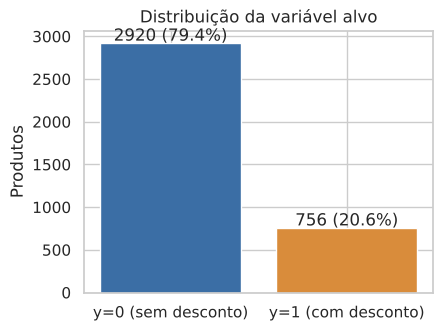

In [5]:
contagem = y.value_counts().sort_index()
prop = y.value_counts(normalize=True).sort_index()
print(pd.DataFrame({"n": contagem, "proporção": prop.round(4)}))
baseline = prop.max()
print(f"\nBaseline (prever sempre y=0): accuracy = {baseline:.4f}")

fig, ax = plt.subplots(figsize=(4.5, 3.4))
ax.bar(["y=0 (sem desconto)", "y=1 (com desconto)"], contagem.values, color=[COR, "#d98c3b"])
for i, v in enumerate(contagem.values):
    ax.text(i, v + 30, f"{v} ({prop.values[i]*100:.1f}%)", ha="center")
ax.set_ylabel("Produtos"); ax.set_title("Distribuição da variável alvo")
guardar_fig("01_target")

### Análise descritiva das variáveis contínuas (`x*`)

In [6]:
desc_x = X[x_vars].describe().T
desc_x["distintos"] = X[x_vars].nunique()
desc_x["assimetria"] = X[x_vars].skew()
desc_x["nulos"] = X[x_vars].isna().sum()
desc_x = desc_x[["count", "nulos", "mean", "std", "min", "25%", "50%", "75%", "max", "distintos", "assimetria"]].round(3)
desc_x.to_csv(TAB / "descritiva_x.csv")
desc_x

,count,nulos,mean,std,min,25%,50%,75%,max,distintos,assimetria
x1,3676.0,0,4.030,2.000,1.000,2.00,4.00,6.00,7.00,7,-0.025
x2,3676.0,0,2.052,0.980,1.000,1.00,2.00,3.00,4.00,4,0.473
x3,3676.0,0,0.549,0.391,0.001,0.35,0.50,0.75,5.00,72,3.805
x4,3676.0,0,1.106,0.317,1.000,1.00,1.00,1.00,3.00,3,2.847
x5,3676.0,0,2.581,2.781,0.390,1.09,1.69,2.82,27.48,181,3.579
x6,3676.0,0,5.985,4.768,1.000,1.00,5.00,8.00,17.00,15,0.730
x7,3676.0,0,8.892,7.403,1.000,4.00,6.00,12.00,25.00,25,1.047
x8,3676.0,0,4.310,1.622,1.000,3.00,4.00,5.00,12.00,12,0.662
x9,3627.0,49,26.317,15.518,1.000,13.50,28.00,40.00,54.00,54,-0.130


As variáveis `x*` não são todas verdadeiramente contínuas: `x1`, `x2` e `x4` têm 7, 4 e 3 valores distintos, e `x6`, `x7` e `x8` só tomam valores inteiros (15, 25 e 12 valores distintos).
`x3`, `x4` e `x5` são muito assimétricas à direita (assimetria entre 2,8 e 3,8). Só a `x9` tem valores em falta.

### Análise descritiva das variáveis discretas (`d*`)

In [7]:
linhas = []
for v in d_vars:
    ativo = X[v] == 1
    linhas.append({"variável": v, "n (d=1)": int(ativo.sum()), "% dos produtos": round(ativo.mean() * 100, 1),
                   "P(y=1 | d=1)": round(y[ativo].mean(), 3), "P(y=1 | d=0)": round(y[~ativo].mean(), 3)})
desc_d = pd.DataFrame(linhas).set_index("variável")
desc_d.to_csv(TAB / "descritiva_d.csv")
print(desc_d.to_string())

n_ativas = X[d_vars].sum(axis=1)
print("\nNº de variáveis d* ativas por produto (%):")
print((n_ativas.clip(upper=3).value_counts(normalize=True).sort_index() * 100).round(1).rename({3: "3 ou mais"}).to_string())

          n (d=1)  % dos produtos  P(y=1 | d=1)  P(y=1 | d=0)
variável                                                     
d1            218             5.9         0.303         0.200
d2            513            14.0         0.248         0.199
d3             74             2.0         0.216         0.205
d4            627            17.1         0.250         0.196
d5            417            11.3         0.031         0.228
d7             56             1.5         0.232         0.205
d8             75             2.0         0.333         0.203
d9            472            12.8         0.110         0.220
d10            98             2.7         0.092         0.209
d11           224             6.1         0.500         0.187
d12            85             2.3         0.271         0.204
d13           248             6.7         0.270         0.201
d14           186             5.1         0.161         0.208
d15           103             2.8         0.010         0.211
d16     

As `d*` são **indicadores binários independentes** e não as categorias de uma única variável: 75,5% dos produtos têm exatamente uma ativa,
10,1% não têm nenhuma e 14,4% têm mais do que uma. A taxa de promoção varia muito entre elas, de 1% na `d15` e 3% na `d5` até 50% na `d11`.

### Treino e task têm distribuições parecidas?

In [8]:
comp = pd.DataFrame({"média treino": X.mean(), "média task": X_task.mean()})
comp["diferença (em desvios-padrão)"] = ((comp["média task"] - comp["média treino"]) / X.std()).round(3)
comp = comp.round(3)
print(comp.to_string())
print("\nMaior diferença absoluta:", comp["diferença (em desvios-padrão)"].abs().max())

     média treino  média task  diferença (em desvios-padrão)
d1          0.059       0.059                         -0.001
d2          0.140       0.126                         -0.040
d3          0.020       0.020                          0.000
d4          0.171       0.179                          0.022
d5          0.113       0.111                         -0.007
d7          0.015       0.016                          0.007
d8          0.020       0.016                         -0.031
d9          0.128       0.138                          0.028
d10         0.027       0.027                          0.000
d11         0.061       0.058                         -0.011
d12         0.023       0.023                         -0.004
d13         0.067       0.069                          0.005
d14         0.051       0.049                         -0.009
d15         0.028       0.029                          0.007
d16         0.028       0.030                          0.013
d17         0.028       

As médias de todas as variáveis são praticamente iguais no treino e no `task` (a maior diferença é de 0,04 desvios-padrão), por isso o `task` vem da mesma população do treino.

### Histogramas

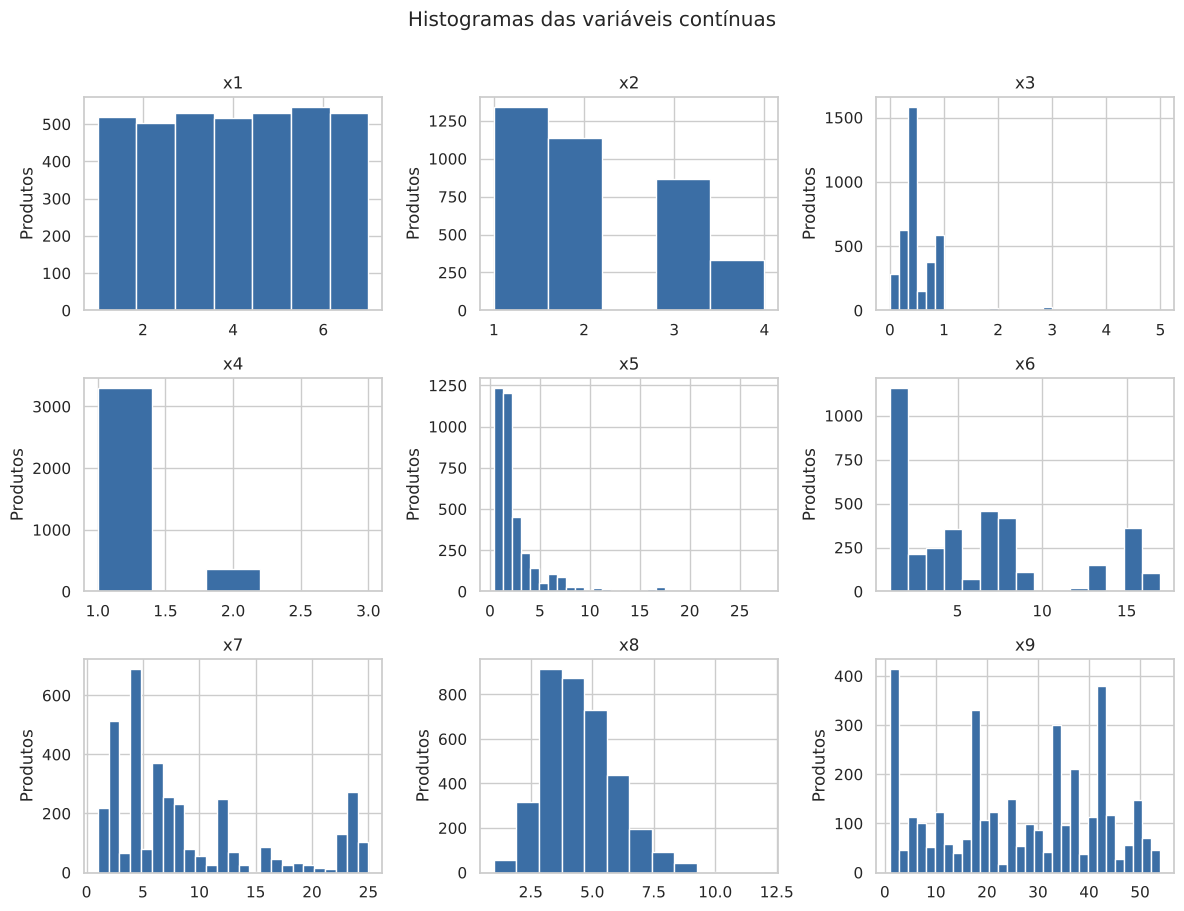

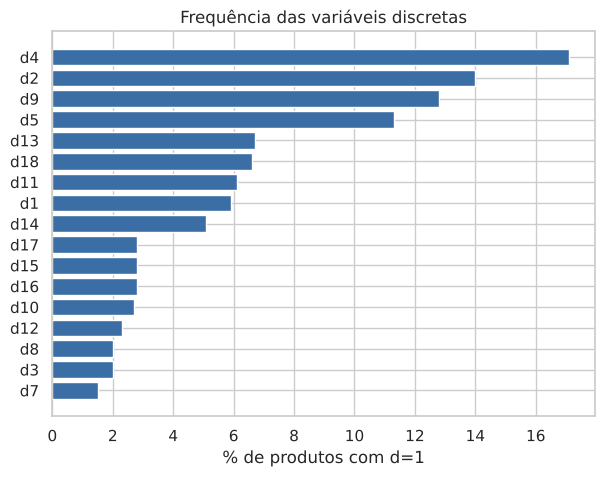

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(12, 9))
for ax, v in zip(axes.flat, x_vars):
    ax.hist(X[v].dropna(), bins=min(30, max(5, X[v].nunique())), color=COR, edgecolor="white")
    ax.set_title(v); ax.set_ylabel("Produtos")
fig.suptitle("Histogramas das variáveis contínuas", y=1.01)
plt.tight_layout(); guardar_fig("02_histogramas_x")

fig, ax = plt.subplots(figsize=(7, 5))
ordem = desc_d["% dos produtos"].sort_values().index
ax.barh(ordem, desc_d.loc[ordem, "% dos produtos"], color=COR)
ax.set_xlabel("% de produtos com d=1"); ax.set_title("Frequência das variáveis discretas")
guardar_fig("03_frequencia_d")

### Boxplots

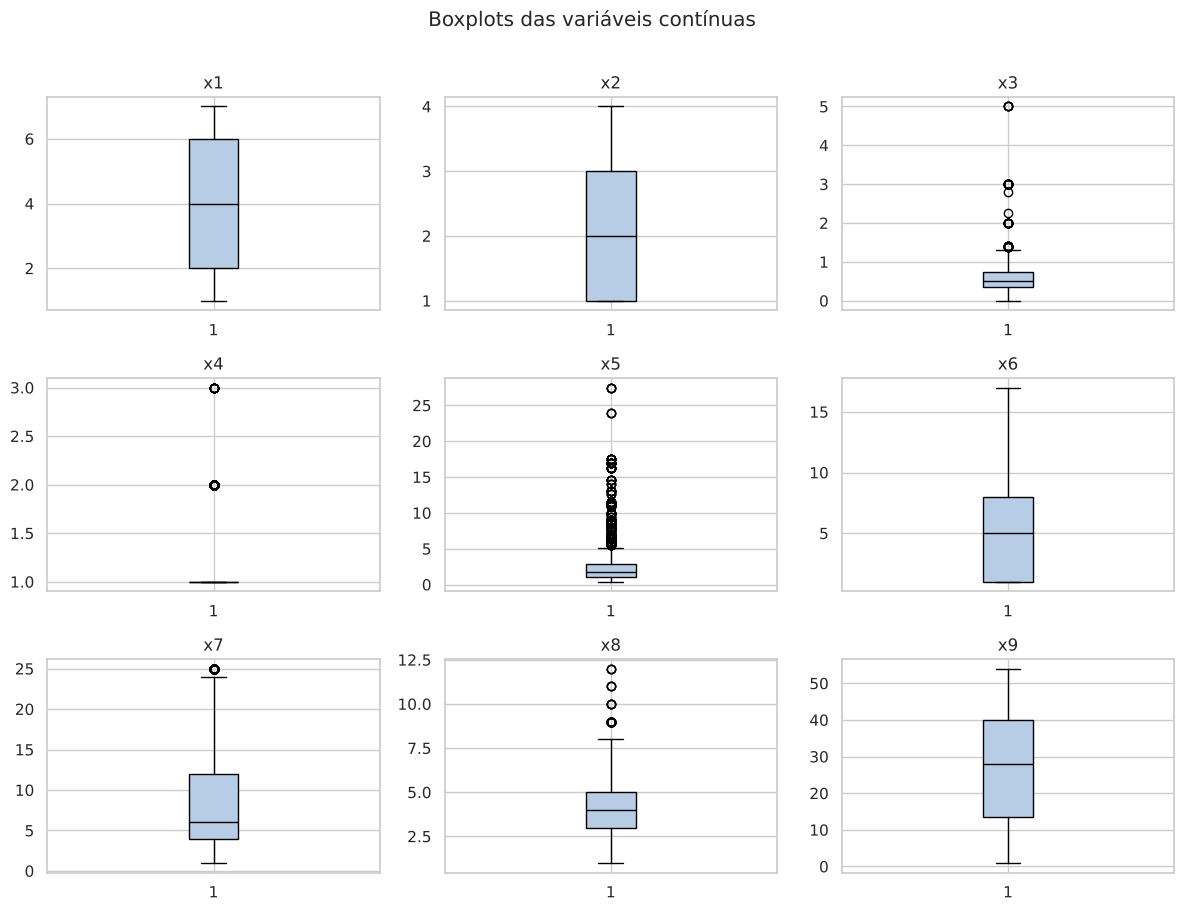

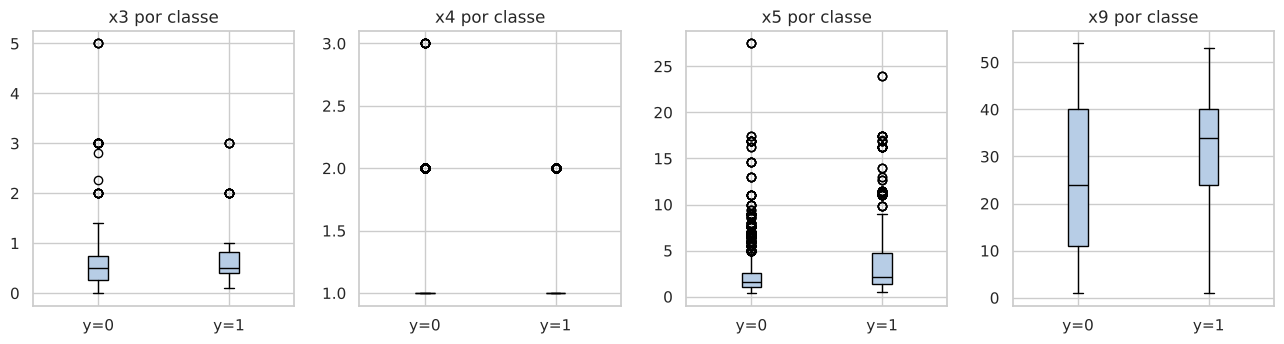

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(12, 9))
for ax, v in zip(axes.flat, x_vars):
    ax.boxplot(X[v].dropna(), patch_artist=True, boxprops=dict(facecolor="#b7cde6"), medianprops=dict(color="black"))
    ax.set_title(v)
fig.suptitle("Boxplots das variáveis contínuas", y=1.01)
plt.tight_layout(); guardar_fig("04_boxplots_x")

fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, v in zip(axes, ["x3", "x4", "x5", "x9"]):
    dados = [X.loc[y == c, v].dropna() for c in (0, 1)]
    ax.boxplot(dados, tick_labels=["y=0", "y=1"], patch_artist=True, boxprops=dict(facecolor="#b7cde6"),
               medianprops=dict(color="black"))
    ax.set_title(f"{v} por classe")
plt.tight_layout(); guardar_fig("05_boxplots_x_por_y")

### Correlações

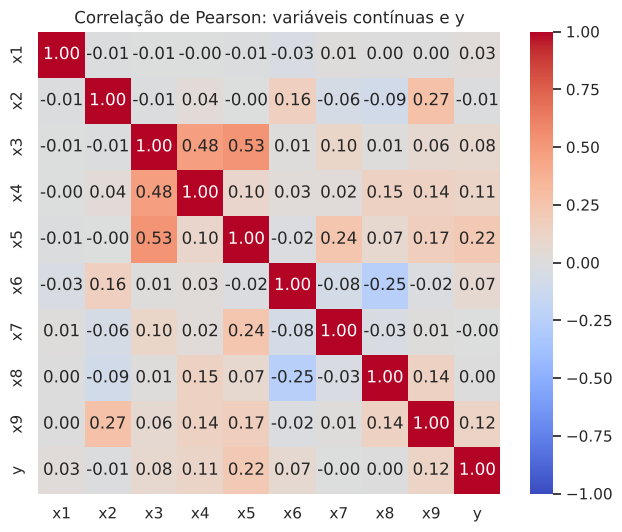

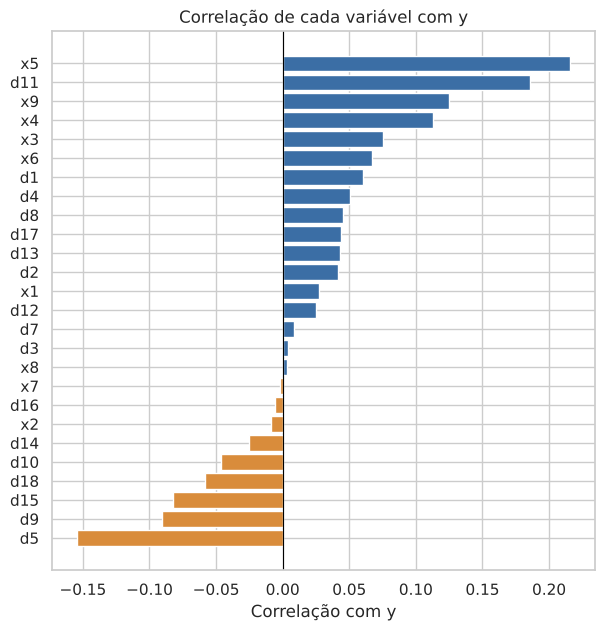

x5     0.216
d11    0.186
d5    -0.154
x9     0.125
x4     0.113
d9    -0.091
d15   -0.082
x3     0.076


In [11]:
corr_x = pd.concat([X[x_vars], y], axis=1).corr()
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr_x, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlação de Pearson: variáveis contínuas e y")
guardar_fig("06_correlacao_x")

corr_y = pd.concat([X, y], axis=1).corr()["y"].drop("y").sort_values()
fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(corr_y.index, corr_y.values, color=[COR if v >= 0 else "#d98c3b" for v in corr_y.values])
ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("Correlação com y")
ax.set_title("Correlação de cada variável com y")
guardar_fig("07_correlacao_com_y")
print(corr_y.round(3).sort_values(key=abs, ascending=False).head(8).to_string())

Cada variável, sozinha, explica pouco de `y`: a maior correlação é a da `x5` (0,22), seguida da `d11` (0,19), da `d5` (−0,15) e da `x9` (0,13).
Isto sugere que o sinal está nas **interações** entre variáveis, o que favorece modelos baseados em árvores.

### Outras verificações: variáveis quase constantes e linhas duplicadas

In [12]:
quase_const = X.apply(lambda s: s.value_counts(normalize=True, dropna=False).max()).sort_values(ascending=False)
print("Maior frequência relativa de um único valor (top 6):")
print(quase_const.head(6).round(3).to_string())

dup_mask = X.duplicated(keep=False)
grupos = X[dup_mask].assign(y=y[dup_mask]).groupby(list(X.columns), dropna=False)["y"].agg(["nunique", "size"])
print(f"\nLinhas repetidas (ignorando o i): {X.duplicated().sum()} a remover, {dup_mask.sum()} linhas em {len(grupos)} grupos")
print("Grupos com y contraditório:", int((grupos['nunique'] > 1).sum()))

chave = lambda df: df.round(4).fillna(-1).astype(str).agg("|".join, axis=1)
em_treino = set(chave(X))
n_igual = chave(X_task).isin(em_treino).sum()
print(f"Linhas do task iguais a uma linha do treino: {n_igual} ({n_igual/len(X_task)*100:.1f}%)")
print(f"Linhas do treino com duplicado no próprio treino: {dup_mask.mean()*100:.1f}%")

Maior frequência relativa de um único valor (top 6):
d7     0.985
d3     0.980
d8     0.980
d12    0.977
d10    0.973
d15    0.972

Linhas repetidas (ignorando o i): 170 a remover, 325 linhas em 155 grupos
Grupos com y contraditório: 0


Linhas do task iguais a uma linha do treino: 382 (10.4%)
Linhas do treino com duplicado no próprio treino: 8.8%


Nenhuma variável é constante (a mais dominante, `d7`, tem só 1,5% de valores a 1, mas todas variam).
Há linhas repetidas, mas **nunca com `y` diferente**, por isso não parecem erros: são produtos com as mesmas características.
Como o `task` também tem linhas iguais a linhas do treino, em proporção parecida (10,4% contra 8,8%), a validação cruzada reproduz bem o que vai acontecer no `task`.
Por isso **não removo duplicados**: removê-los não se aplica ao `task` e alteraria a proporção que o modelo vai encontrar.

# Data preparation

Para decidir cada tratamento comparo alternativas com **validação cruzada de 10 folds estratificados** e três modelos simples:
Random Forest, árvore de decisão (profundidade 6) e KNN (k=15, com normalização). Tudo o que aprende com os dados
(mediana, normalização, SMOTE) está dentro do `Pipeline`, por isso é calculado só com os dados de treino de cada fold e não há *data leakage*.

In [13]:
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
SCORING = {"accuracy": "accuracy", "recall": "recall", "precision": "precision", "f1": "f1"}


def cv_linha(nome, pipe, dados=X):
    r = cross_validate(pipe, dados, y, cv=skf, scoring=SCORING, n_jobs=-1)
    return {"alternativa": nome, "accuracy": r["test_accuracy"].mean(), "desvio acc.": r["test_accuracy"].std(),
            "recall": r["test_recall"].mean(), "precision": r["test_precision"].mean(), "f1": r["test_f1"].mean()}


def imputador(indicador=True, pandas_out=True):
    imp = SimpleImputer(strategy="median", add_indicator=indicador)
    return imp.set_output(transform="pandas") if pandas_out else imp


rf = lambda **k: RandomForestClassifier(n_estimators=200, random_state=SEED, **k)
dt = lambda **k: DecisionTreeClassifier(max_depth=6, random_state=SEED, **k)
knn = lambda: KNeighborsClassifier(n_neighbors=15)
print(f"Baseline: {baseline:.4f}")

Baseline: 0.7943


## Missing values

In [14]:
nulos = pd.DataFrame({"nulos treino": X.isna().sum(), "nulos task": X_task.isna().sum()})
print(nulos[nulos.sum(axis=1) > 0].to_string())

falta = X["x9"].isna()
print(f"\nTaxa de y=1 quando x9 falta: {y[falta].mean():.3f} (n={falta.sum()})  |  quando x9 existe: {y[~falta].mean():.3f}")

    nulos treino  nulos task
x9            49          30

Taxa de y=1 quando x9 falta: 0.000 (n=49)  |  quando x9 existe: 0.208


Só a `x9` tem valores em falta, 49 no treino e 30 no `task`. As três opções:

1. **Remover as linhas:** perde 49 produtos e não se aplica ao `task`, onde é preciso prever todas as linhas.
2. **Imputar a mediana.**
3. **Imputar a mediana e acrescentar um indicador de “x9 em falta”.** As 49 linhas têm todas `y=0`, por isso a falta é, em si, informação.

Comparo as opções 2 e 3 (a opção 1 não é possível no `task`):

In [15]:
linhas = []
for nome, ind in (("mediana", False), ("mediana + indicador", True)):
    linhas.append({"modelo": "RF", **cv_linha(nome, Pipeline([("i", imputador(ind)), ("m", rf())]))})
    linhas.append({"modelo": "DT", **cv_linha(nome, Pipeline([("i", imputador(ind)), ("m", dt())]))})
    linhas.append({"modelo": "KNN", **cv_linha(nome, Pipeline([("i", imputador(ind)), ("s", StandardScaler()), ("m", knn())]))})
exp_missing = pd.DataFrame(linhas).set_index(["modelo", "alternativa"]).round(4)
exp_missing.to_csv(TAB / "experiencia_missing.csv")
exp_missing

,,accuracy,desvio acc.,recall,precision,f1
modelo,alternativa,,,,,
RF,mediana,0.9554,0.0084,0.8625,0.9171,0.8881
DT,mediana,0.8599,0.0093,0.4574,0.7814,0.5692
KNN,mediana,0.8156,0.0096,0.3174,0.6005,0.4127
RF,mediana + indicador,0.9554,0.0100,0.8598,0.9191,0.8877
DT,mediana + indicador,0.8594,0.0098,0.4574,0.7779,0.5683
KNN,mediana + indicador,0.8177,0.0092,0.3240,0.6101,0.4209


**Decisão:** imputar a **mediana (calculada só no treino) e acrescentar o indicador de falta**. A diferença de accuracy é pequena (dentro do desvio-padrão, de cerca de 1 ponto percentual),
mas o indicador não custa nada, aproveita o facto de todas as linhas em falta terem `y=0` e funciona igual no `task`.

## Outliers

In [16]:
def conta_outliers(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

out = pd.DataFrame({"outliers (IQR)": X[x_vars].apply(conta_outliers)})
out["% do treino"] = (100 * out["outliers (IQR)"] / len(X)).round(2)
out.to_csv(TAB / "outliers.csv")
print(out.to_string())

sinalizados = pd.concat({v: ((X[v] < X[v].quantile(.25) - 1.5 * (X[v].quantile(.75) - X[v].quantile(.25))) |
                             (X[v] > X[v].quantile(.75) + 1.5 * (X[v].quantile(.75) - X[v].quantile(.25)))) for v in x_vars}, axis=1)
print(f"\nProdutos com pelo menos um outlier: {sinalizados.any(axis=1).sum()} ({sinalizados.any(axis=1).mean()*100:.1f}%)")
print("\nValores de x4:", X["x4"].value_counts().sort_index().to_dict())
print("x5: mínimo", X["x5"].min(), "| mediana", X["x5"].median(), "| p99", round(X["x5"].quantile(.99), 2), "| máximo", X["x5"].max())

    outliers (IQR)  % do treino
x1               0         0.00
x2               0         0.00
x3              61         1.66
x4             377        10.26
x5             374        10.17
x6               0         0.00
x7             103         2.80
x8              55         1.50
x9               0         0.00

Produtos com pelo menos um outlier: 844 (23.0%)

Valores de x4: {1: 3299, 2: 366, 3: 11}
x5: mínimo 0.39 | mediana 1.69 | p99 16.29 | máximo 27.48


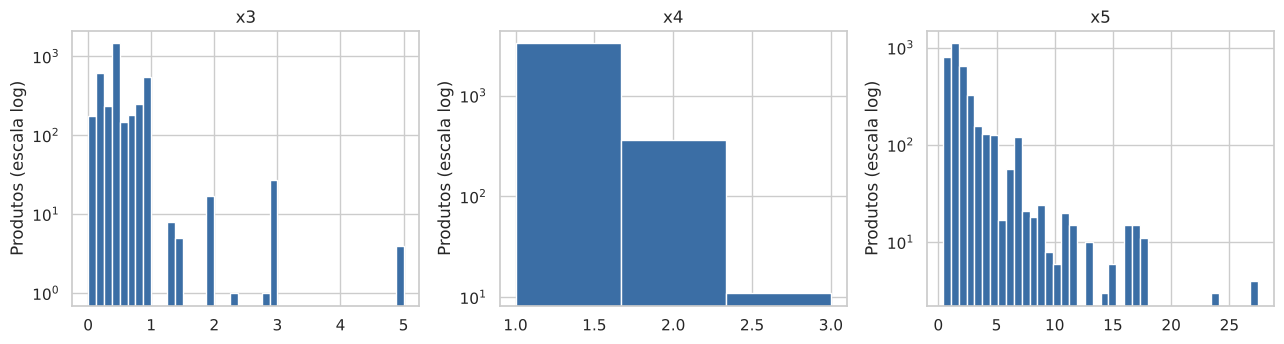

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, v in zip(axes, ["x3", "x4", "x5"]):
    ax.hist(X[v], bins=min(40, X[v].nunique()), color=COR, edgecolor="white"); ax.set_title(f"{v}"); ax.set_yscale("log")
    ax.set_ylabel("Produtos (escala log)")
plt.tight_layout(); guardar_fig("08_outliers_x3_x4_x5")

Os outliers concentram-se em `x4` e `x5` (cerca de 10% cada). Não parecem erros de dados:
- a `x4` só toma os valores 1, 2 e 3, e os “outliers” são os valores 2 e 3, que são categorias legítimas;
- a `x5` é uma variável com cauda longa à direita (mediana 1,69, máximo 27,48), típica de valores monetários.

Cerca de um quarto dos produtos tem pelo menos um outlier, por isso **removê-los** apagaria muita informação e não seria possível no `task`.
Testo as alternativas de os manter, de os limitar aos percentis 1% e 99% (*winsorizing*) e de aplicar `log(1+x)` à `x3` e à `x5`:

In [18]:
class Winsorizer(BaseEstimator, TransformerMixin):
    """Limita as colunas aos percentis de treino (aprendidos só no fit)."""
    def __init__(self, colunas, baixo=0.01, alto=0.99):
        self.colunas, self.baixo, self.alto = colunas, baixo, alto
    def fit(self, X, y=None):
        self.lo_, self.hi_ = X[self.colunas].quantile(self.baixo), X[self.colunas].quantile(self.alto)
        return self
    def transform(self, X):
        X = X.copy(); X[self.colunas] = X[self.colunas].clip(self.lo_, self.hi_, axis=1); return X
    def set_output(self, *, transform=None):
        return self


def log_x3_x5():
    ct = ColumnTransformer([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), ["x3", "x5"])],
                           remainder="passthrough", verbose_feature_names_out=False)
    return ct.set_output(transform="pandas")


linhas = [
    {"modelo": "KNN", **cv_linha("manter", Pipeline([("i", imputador()), ("s", StandardScaler()), ("m", knn())]))},
    {"modelo": "KNN", **cv_linha("winsorizing 1-99%", Pipeline([("i", imputador()), ("w", Winsorizer(x_vars)), ("s", StandardScaler()), ("m", knn())]))},
    {"modelo": "KNN", **cv_linha("log(1+x) em x3 e x5", Pipeline([("i", imputador()), ("l", log_x3_x5()), ("s", StandardScaler()), ("m", knn())]))},
    {"modelo": "RF", **cv_linha("manter", Pipeline([("i", imputador()), ("m", rf())]))},
    {"modelo": "RF", **cv_linha("winsorizing 1-99%", Pipeline([("i", imputador()), ("w", Winsorizer(x_vars)), ("m", rf())]))},
]
exp_outliers = pd.DataFrame(linhas).set_index(["modelo", "alternativa"]).round(4)
exp_outliers.to_csv(TAB / "experiencia_outliers.csv")
exp_outliers

accuracy  desvio acc.  recall  precision      f1
modelo alternativa                                                          
KNN    manter                 0.8177       0.0092  0.3240     0.6101  0.4209
       winsorizing 1-99%      0.8169       0.0098  0.3214     0.6081  0.4184
       log(1+x) em x3 e x5    0.8158       0.0072  0.3147     0.6024  0.4113
RF     manter                 0.9554       0.0100  0.8598     0.9191  0.8877
       winsorizing 1-99%      0.9565       0.0073  0.8651     0.9200  0.8909

**Decisão:** **manter os outliers sem alterações**. Nenhum tratamento melhora a accuracy mais do que o desvio-padrão dos folds (cerca de 1 ponto percentual),
os valores extremos são legítimos e as árvores são robustas a eles.

## Dados desbalanceados

In [19]:
cat_idx = list(range(len(d_vars))) + [X.shape[1]]   # as d* e o indicador de x9 em falta (última coluna) são binárias
smote = lambda: SMOTENC(categorical_features=cat_idx, random_state=SEED)
imp_np = lambda: imputador(True, pandas_out=False)

linhas = []
for nome, pipe in (
    ("RF · sem equilíbrio", Pipeline([("i", imp_np()), ("m", rf())])),
    ("RF · class_weight=balanced", Pipeline([("i", imp_np()), ("m", rf(class_weight="balanced"))])),
    ("RF · SMOTENC", ImbPipeline([("i", imp_np()), ("o", smote()), ("m", rf())])),
    ("DT · sem equilíbrio", Pipeline([("i", imp_np()), ("m", dt())])),
    ("DT · class_weight=balanced", Pipeline([("i", imp_np()), ("m", dt(class_weight="balanced"))])),
    ("DT · SMOTENC", ImbPipeline([("i", imp_np()), ("o", smote()), ("m", dt())])),
    ("KNN · sem equilíbrio", Pipeline([("i", imp_np()), ("s", StandardScaler()), ("m", knn())])),
    ("KNN · SMOTENC", ImbPipeline([("i", imp_np()), ("o", smote()), ("s", StandardScaler()), ("m", knn())])),
):
    linhas.append(cv_linha(nome, pipe))
exp_balance = pd.DataFrame(linhas).set_index("alternativa").round(4)
exp_balance.to_csv(TAB / "experiencia_desbalanceamento.csv")
exp_balance

,accuracy,desvio acc.,recall,precision,f1
alternativa,,,,,
RF · sem equilíbrio,0.9554,0.0100,0.8598,0.9191,0.8877
RF · class_weight=balanced,0.9559,0.0074,0.9088,0.8812,0.8946
RF · SMOTENC,0.9573,0.0091,0.8783,0.9126,0.8944
DT · sem equilíbrio,0.8594,0.0098,0.4574,0.7779,0.5683
DT · class_weight=balanced,0.7506,0.0447,0.8321,0.4511,0.5813
DT · SMOTENC,0.7573,0.0364,0.7830,0.4542,0.5721
KNN · sem equilíbrio,0.8177,0.0092,0.3240,0.6101,0.4209
KNN · SMOTENC,0.7312,0.0226,0.7432,0.4148,0.5319


Equilibrar as classes **aumenta sempre o Recall**, mas só ajuda a accuracy no Random Forest (e dentro do ruído). Na árvore de decisão e no KNN faz a accuracy cair entre 9 e 11 pontos,
porque o modelo passa a prever `y=1` com demasiada frequência.

**Decisão:** como a métrica é a accuracy, **não equilibro as classes** nos modelos principais. No Notebook 2 o Random Forest é também testado com `class_weight="balanced"` para mostrar o compromisso entre accuracy e Recall.

## Features redundantes

Pares de variáveis com |correlação| > 0,5:
variável 1 variável 2  correlação
        d1         x4        0.71
       d10        d13        0.62
        x3         x5        0.53

Maior |correlação| entre variáveis: 0.71

d1 contra x4 (a d1 só aparece com x4=2):
x4     1    2   3
d1               
0   3299  148  11
1      0  218   0


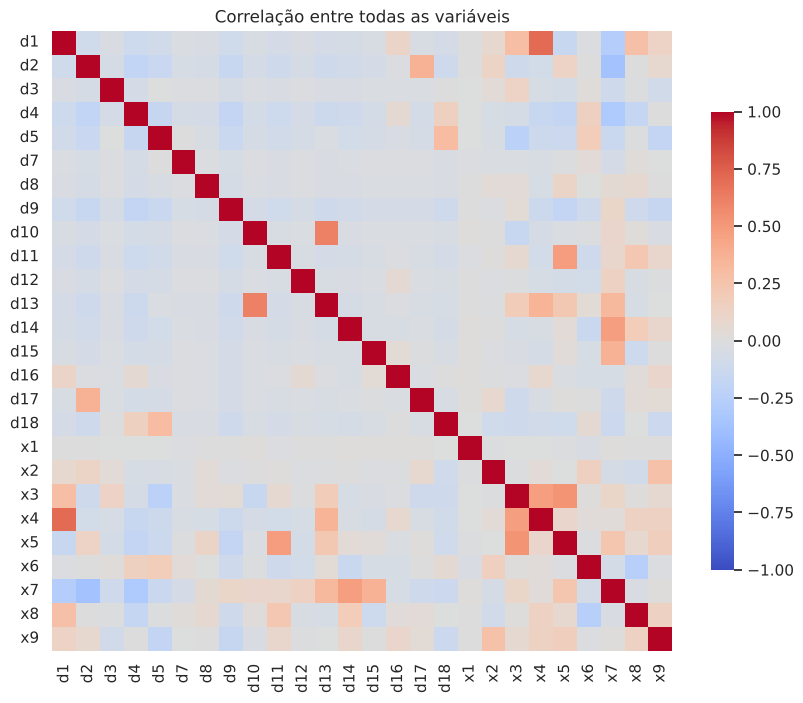

In [20]:
corr_all = X.corr()
pares = [(a, b, round(corr_all.loc[a, b], 2)) for i, a in enumerate(corr_all.columns) for b in corr_all.columns[i + 1:]
         if abs(corr_all.loc[a, b]) > 0.5]
print("Pares de variáveis com |correlação| > 0,5:")
print(pd.DataFrame(pares, columns=["variável 1", "variável 2", "correlação"]).to_string(index=False))
print("\nMaior |correlação| entre variáveis:", round(max(abs(c) for *_, c in pares), 2))
print("\nd1 contra x4 (a d1 só aparece com x4=2):")
print(pd.crosstab(X["d1"], X["x4"]).to_string())

fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(corr_all, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Correlação entre todas as variáveis"); guardar_fig("09_correlacao_todas")

In [21]:
linhas = []
for nome, tirar in (("todas", []), ("sem d1", ["d1"]), ("sem x4", ["x4"]), ("sem d13", ["d13"]), ("sem x3", ["x3"]),
                    ("sem d1, d13 e x3", ["d1", "d13", "x3"])):
    dados = X.drop(columns=tirar)
    linhas.append({"modelo": "RF", **cv_linha(nome, Pipeline([("i", imputador()), ("m", rf())]), dados)})
    linhas.append({"modelo": "KNN", **cv_linha(nome, Pipeline([("i", imputador()), ("s", StandardScaler()), ("m", knn())]), dados)})
exp_redund = pd.DataFrame(linhas).set_index(["modelo", "alternativa"]).round(4)
exp_redund.to_csv(TAB / "experiencia_redundancia.csv")
exp_redund

,,accuracy,desvio acc.,recall,precision,f1
modelo,alternativa,,,,,
RF,todas,0.9554,0.0100,0.8598,0.9191,0.8877
KNN,todas,0.8177,0.0092,0.3240,0.6101,0.4209
RF,sem d1,0.9562,0.0082,0.8625,0.9211,0.8900
KNN,sem d1,0.8166,0.0089,0.3187,0.6063,0.4154
RF,sem x4,0.9562,0.0103,0.8599,0.9230,0.8895
KNN,sem x4,0.8161,0.0098,0.3160,0.6047,0.4127
RF,sem d13,0.9557,0.0096,0.8599,0.9206,0.8884
KNN,sem d13,0.8180,0.0097,0.3279,0.6098,0.4246
RF,sem x3,0.9559,0.0067,0.8532,0.9279,0.8882


Os pares mais correlacionados são `d1`–`x4` (0,71), `d10`–`d13` (0,62) e `x3`–`x5` (0,53), uma correlação **moderada**.
A `d1` está contida na `x4`: sempre que `d1=1`, a `x4` vale 2. Retirar uma variável de cada par, ou as três de uma vez, não altera a accuracy mais do que o desvio-padrão.

**Decisão:** **manter todas as variáveis**. Nenhuma correlação passa o limiar habitual de 0,8, e remover variáveis não traz ganho mensurável.

## Create cross-validation data

In [22]:
folds = pd.DataFrame({"i": training["i"], "fold": -1})
for k, (_, idx_teste) in enumerate(skf.split(X, y)):
    folds.loc[idx_teste, "fold"] = k
folds.to_csv(OUT / "folds.csv", index=False)

resumo = folds.assign(y=y.values).groupby("fold")["y"].agg(["size", "mean"]).round(3)
resumo.columns = ["produtos no fold", "proporção y=1"]
print(resumo.to_string())
print("\nOs 10 folds têm tamanho e proporção de y=1 praticamente iguais (estratificação).")

      produtos no fold  proporção y=1
fold                                 
0                  368          0.207
1                  368          0.207
2                  368          0.207
3                  368          0.207
4                  368          0.207
5                  368          0.207
6                  367          0.204
7                  367          0.204
8                  367          0.204
9                  367          0.204

Os 10 folds têm tamanho e proporção de y=1 praticamente iguais (estratificação).


## Resumo das decisões de Data preparation

| Tema | Decisão | Justificação |
|---|---|---|
| Identificador | Retirar `i` | É só o número do registo |
| Missing values | Mediana + indicador de falta (`x9`) | 49 linhas, todas com `y=0`; impossível remover no `task` |
| Duplicados | Manter | 170 linhas, nenhuma com `y` contraditório; o `task` também tem repetidas |
| Outliers | Manter | Valores legítimos; winsorizing e `log` não melhoram a accuracy |
| Dados desbalanceados | Não equilibrar (testar `class_weight` no RF) | O equilíbrio baixa a accuracy na árvore e no KNN |
| Features redundantes | Manter todas | Correlação máxima de 0,71 (`d1`–`x4`), abaixo do limiar de 0,8 |
| Normalização | Só para KNN, MLP e Naive Bayes | Escalas muito diferentes (`x3` até 5, `x9` até 54) |
| Cross-validation | 10 folds estratificados, semente 42 | Mesmos folds para todos os modelos |

O **Notebook 2** usa estas decisões dentro de um `Pipeline`, treina os 7 modelos e compara-os.